# Neuroworkshop — local setup

This notebook uses **GSSC**. Download the complete repository, extract it,
and open **Neuroworkshop_github_final** as a folder in VS Code. Install Python 3.12
and the VS Code **Python** and **Jupyter** extensions before the workshop.
Install Git too: GSSC is installed from a pinned GitHub revision. Run these commands **once**, in a terminal at the repository root:

**macOS / Linux**
```bash
python3.12 -m venv .venv-gssc
.venv-gssc/bin/python -m pip install -r requirements-gssc.txt
```

**Windows PowerShell**
```powershell
py -3.12 -m venv .venv-gssc
.\.venv-gssc\Scripts\python.exe -m pip install -r requirements-gssc.txt
```

In this notebook, click **Select Kernel → Python Environments → .venv-gssc**.
The terminal and notebook select Python independently. Restart the kernel after
switching, then run the cells from the beginning with **Shift+Enter**.
Notebooks 01–03 use `.venv-yasa`; notebook 04 uses `.venv-gssc`.

Internet access is needed for package installation and the first public sample
download. Later runs reuse the local `data/` cache. Results are generated in
`outputs/`. CPU is sufficient. Installation is preparation, outside the lesson.
Virtual environments in the facilitator's local folder are machine-specific;
attendees create their own from the requirements above.


In [1]:
import subprocess
import sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/jshanna100/gssc.git@2da29b0715242f3a76b0daab2ba7d593a91eb7f8",
        "mne>=1.7,<2", "torch>=2.6,<3", "pooch>=1.8,<2", "ipywidgets>=8,<9",
    ])
else:
    print("Local mode: select .venv-gssc as the kernel.")

Local mode: select .venv-gssc as the kernel.


# Getting started with GSSC

We use the original repository accompanying Hanna & Floel (2023):
https://github.com/jshanna100/gssc
https://doi.org/10.3389/fninf.2023.1086634

By the end, you can load EEG/EOG, predict sleep stages, inspect probabilities,
and flag uncertain epochs. An optional extension demonstrates the documented
epoch-by-epoch API. This is a recorded-data lesson with no stimulation control.


In [2]:
import importlib.metadata as metadata
import json
import os
from pathlib import Path
import sys
from time import perf_counter

GSSC_COMMIT = "2da29b0715242f3a76b0daab2ba7d593a91eb7f8"
GSSC_REPOSITORY = "https://github.com/jshanna100/gssc"

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Find the downloaded repository; no source/helper folder is required.
if IN_COLAB:
    WORKSHOP = Path.cwd() / "Neuroworkshop_github_final"
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    WORKSHOP = next((p for p in candidates if (p / "requirements-yasa.txt").is_file()
                     and (p / "requirements-gssc.txt").is_file()), None)
    if WORKSHOP is None:
        raise RuntimeError("Open the complete Neuroworkshop_github_final folder in VS Code, including its requirements files.")
WORKSHOP.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(WORKSHOP / ".mplconfig-gssc"))

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pooch
import torch
from gssc.infer import EEGInfer
from IPython.display import display

# CPU is sufficient for this small example; no NVIDIA GPU is required.
torch.set_num_threads(2)
mne.set_log_level("ERROR")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT = WORKSHOP / "outputs" / "gssc_workshop"
OUT.mkdir(parents=True, exist_ok=True)
STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])
PROBABILITY_COLUMNS = [f"P_{stage}" for stage in STAGE_NAMES]
versions = {name: metadata.version(name) for name in ["gssc", "torch", "mne", "numpy", "scipy", "pandas"]}
source_info = json.loads(metadata.distribution("gssc").read_text("direct_url.json") or "{}")
installed_commit = source_info.get("vcs_info", {}).get("commit_id")
if installed_commit != GSSC_COMMIT:
    raise RuntimeError("Install the pinned GitHub revision using requirements-gssc.txt, then select the .venv-gssc notebook kernel.")
print("Python:", sys.executable)
print("Verified GSSC repository revision:", installed_commit)
print("Installed packages:", versions)
print("Results:", OUT)

Matplotlib is building the font cache; this may take a moment.


Python: <repository>/.venv-gssc/bin/python
Verified GSSC repository revision: 2da29b0715242f3a76b0daab2ba7d593a91eb7f8
Installed packages: {'gssc': '0.0.9', 'torch': '2.15.0', 'mne': '1.13.2', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.1'}
Results: /private<repository>/outputs/gssc_workshop


## 2. Meet the recording
We reuse the **49-minute nap** from the YASA workshop. This is sample data,
not a participant undergoing TIS. C4 (EEG) and EOG1 (eye movements) are inputs.
The supplied reference stages are used only to compare results.

MNE stores signals in **volts**. We request **microvolts** for EEG plots.
**Try:** identify the sampling rate, recording duration and available channels.

In [3]:
samples = pooch.create(
    path=WORKSHOP / "data",
    base_url="https://zenodo.org/records/14564285/files/",
    registry={
        "sub-02_mne_raw.fif": "md5:eb9360c29f21092834bfd67079b3c57e",
        "sub-02_hypno_30s.txt": "md5:bcf75ac8180cdc68c5a6d20f921d1473",
    },
)
raw = mne.io.read_raw_fif(samples.fetch("sub-02_mne_raw.fif"), preload=True, verbose=False)
reference = np.loadtxt(samples.fetch("sub-02_hypno_30s.txt"), dtype=str)
reference = np.array([{"W": "WAKE", "R": "REM"}.get(stage, stage) for stage in reference])
sf = float(raw.info["sfreq"])
assert np.isclose(raw.n_times / sf, len(reference) * 30)
print("Channels:", raw.ch_names)
print(f"Sampling rate: {sf:g} Hz | Duration: {raw.n_times / sf / 60:.1f} min")
display(pd.Series(reference).value_counts().rename("Reference epochs"))

Channels: ['F3', 'F4', 'C3', 'C4', 'O1', 'O2', 'EOG1', 'EOG2', 'EMG1']
Sampling rate: 100 Hz | Duration: 49.0 min


WAKE    36
N2      31
N3      22
N1       9
Name: Reference epochs, dtype: int64

## 3. Run GSSC on the recorded nap
We use the publication's `EEGInfer` API with one explicit EEG/EOG combination.
GSSC's five classes are **Wake, N1, N2, N3, REM**.

The core example uses the full recording for filtering and normalization.
It is an **offline introduction**, not a demonstration of live processing.
The bundled context GRU is BIDIRECTIONAL: predictions can use preceding AND
following epochs. `chunk_n=8` only batches the signal encoder; all epoch
representations then enter the context GRU together. It is not an eight-epoch
context window. `filter=False` below skips an extra filter, not the context GRU.

**Where is the GRU called?** The marked `classifier.mne_infer(...)` line below
enters the wrapper. Inside GSSC it calls `con_net(reps, hidden)` once on the
full sequence of epoch representations, starting with zero hidden state.
The actual PyTorch operation is `self.gru(input, hidden)` inside
[`SleepGRU.forward`](https://github.com/jshanna100/gssc/blob/2da29b0715242f3a76b0daab2ba7d593a91eb7f8/gssc/networks.py#L333).
We explicitly create 30-second epochs to preserve the final complete epoch.
The original `raw` is kept for later signal inspection and replay.

In [4]:
model_input = raw.copy().pick(["C4", "EOG1"])
model_input.filter(l_freq=0.3, h_freq=30, verbose=False)
epochs = mne.make_fixed_length_epochs(model_input, duration=30, preload=True, verbose=False)
assert len(epochs) == len(reference)
classifier = EEGInfer(use_cuda=False, chunk_n=8)  # Loads models; no GRU inference yet.
started = perf_counter()
# GRU call via this wrapper: BIDIRECTIONAL OFFLINE CONTEXT.
# Internally: y, hidden = con_net(reps, hidden), with ALL epochs in reps.
# Prediction for epoch t can use preceding AND following epochs.
# chunk_n=8 only batches the encoder; it does not select forward inference.
stage_codes, start_seconds, probabilities = classifier.mne_infer(
    epochs, eeg=["C4"], eog=["EOG1"], eeg_drop=False, eog_drop=False, filter=False
)
batch_seconds = perf_counter() - started
predicted = STAGE_NAMES[stage_codes]
assert probabilities.shape == (len(reference), 5)
assert np.isfinite(probabilities).all() and np.allclose(probabilities.sum(axis=1), 1)
assert np.array_equal(stage_codes, probabilities.argmax(axis=1))
assert np.allclose(start_seconds, np.arange(len(reference)) * 30)
table = pd.DataFrame({
    "Epoch": np.arange(len(reference)), "Start_s": start_seconds,
    "Reference": reference, "Predicted": predicted,
    "Max_probability": probabilities.max(axis=1),
})
table[PROBABILITY_COLUMNS] = probabilities
agreement = float(np.mean(reference == predicted))
print(f"Computed {len(table)} epochs in {batch_seconds:.2f} seconds on this computer.")
print(f"Agreement with this nap's reference: {100 * agreement:.1f}%")
display(table.head().round(3))

Running without CUDA on CPU. Speed will be suboptimal.
Inferring permutation 1 of 1


Computed 98 epochs in 0.24 seconds on this computer.
Agreement with this nap's reference: 92.9%


,Epoch,Start_s,Reference,Predicted,Max_probability,P_WAKE,P_N1,P_N2,P_N3,P_REM
0,0,0,WAKE,WAKE,0.934,0.934,0.002,0.030,0.020,0.015
1,1,30,WAKE,WAKE,0.991,0.991,0.001,0.003,0.001,0.005
2,2,60,WAKE,WAKE,0.994,0.994,0.002,0.001,0.000,0.003
3,3,90,WAKE,WAKE,0.993,0.993,0.003,0.001,0.000,0.003
4,4,120,WAKE,WAKE,0.991,0.991,0.005,0.002,0.000,0.002


## 4. Inspect the hypnograms
Wake is at the top and N3 at the bottom. Look for transitions and disagreements.
This nap contains **no reference REM**, so it cannot establish REM accuracy.


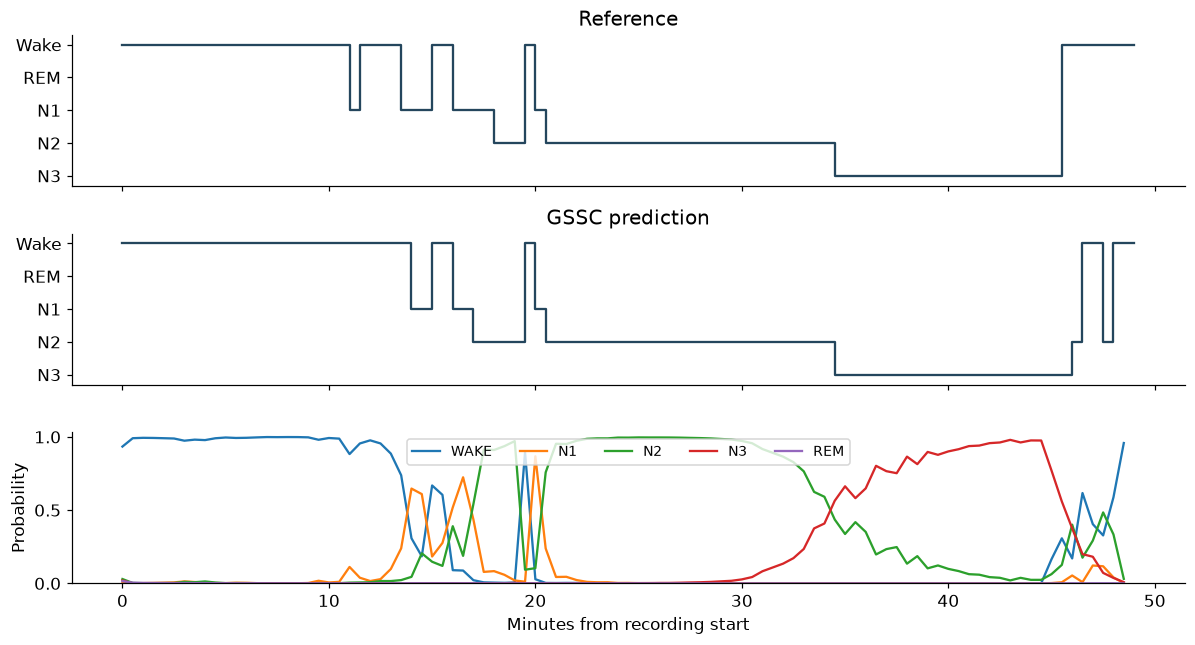

In [5]:
positions = {"N3": 0, "N2": 1, "N1": 2, "REM": 3, "WAKE": 4}
edges_min = np.arange(len(table) + 1) * 0.5
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, labels, title in zip(axes[:2], [reference, predicted], ["Reference", "GSSC prediction"]):
    y = [positions[stage] for stage in labels]
    ax.step(edges_min, [*y, y[-1]], where="post", color="#24465D")
    ax.set(yticks=range(5), yticklabels=["N3", "N2", "N1", "REM", "Wake"],
           ylim=(-0.3, 4.3), title=title)
for column, stage in zip(PROBABILITY_COLUMNS, STAGE_NAMES):
    axes[2].plot(table.Start_s / 60, table[column], label=stage)
axes[2].set(xlabel="Minutes from recording start", ylabel="Probability", ylim=(0, 1.03))
axes[2].legend(ncol=5, loc="upper center", fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "01_hypnograms_and_probabilities.png", dpi=160)
plt.show()

## 5. Try it: change a review cutoff
`Max_probability` is the model's highest stage probability. It describes
confidence in the prediction; it does not establish correctness.

**Predict first:** will moving the cutoff from **0.6 to 0.8** flag more epochs?
Run the helper cell, then change only `review_cutoff` in the next cell.

In [6]:
def review_predictions(cutoff=0.6):
    if not 0 <= cutoff <= 1:
        raise ValueError("Choose a cutoff between 0 and 1.")
    reviewed = table.copy()
    reviewed["Flag_for_review"] = reviewed.Max_probability < cutoff
    fig, ax = plt.subplots(figsize=(11, 2.6))
    ax.plot(reviewed.Start_s / 60, reviewed.Max_probability, color="#24465D")
    flagged = reviewed.Flag_for_review
    ax.scatter(reviewed.loc[flagged, "Start_s"] / 60,
               reviewed.loc[flagged, "Max_probability"], color="#C16A32", zorder=3)
    ax.axhline(cutoff, color="#C16A32", linestyle="--")
    ax.set(xlabel="Time (minutes)", ylabel="Max probability", ylim=(0, 1.03))
    fig.tight_layout()
    fig.savefig(OUT / "02_confidence_review.png", dpi=160)
    plt.show()
    print(f"{int(flagged.sum())} of {len(reviewed)} epochs flagged; stages unchanged.")
    display(reviewed.loc[flagged, ["Epoch", "Reference", "Predicted", "Max_probability"]].round(3))
    return reviewed

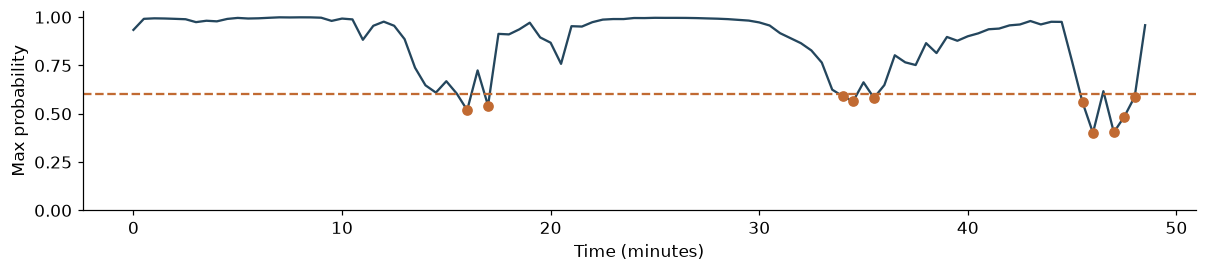

10 of 98 epochs flagged; stages unchanged.


,Epoch,Reference,Predicted,Max_probability
32,32,N1,N1,0.519
34,34,N1,N2,0.542
68,68,N2,N2,0.591
69,69,N3,N3,0.564
71,71,N3,N3,0.582
91,91,WAKE,N3,0.559
92,92,WAKE,N2,0.401
94,94,WAKE,WAKE,0.404
95,95,WAKE,N2,0.484
96,96,WAKE,WAKE,0.588


In [7]:
review_cutoff = 0.6
review_table = review_predictions(review_cutoff)

## 6. Look at the signals behind one prediction
Start with the least-confident epoch. Try a different `epoch_to_inspect` next.

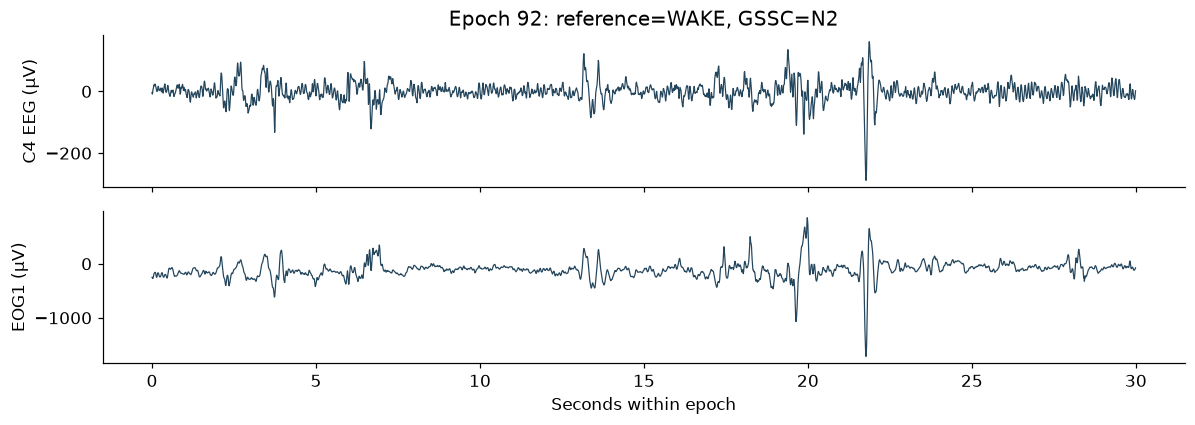

,Epoch,Start_s,Reference,Predicted,Max_probability,P_WAKE,P_N1,P_N2,P_N3,P_REM
92,92,2760,WAKE,N2,0.401,0.17,0.054,0.401,0.375,0.0


In [8]:
def inspect_epoch(epoch):
    epoch = int(epoch)
    if not 0 <= epoch < len(table):
        raise ValueError(f"Choose an epoch from 0 to {len(table) - 1}.")
    start, stop = int(epoch * 30 * sf), int((epoch + 1) * 30 * sf)
    signals_uv = raw.get_data(picks=["C4", "EOG1"], start=start, stop=stop) * 1e6
    fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
    for ax, values, label in zip(axes, signals_uv, ["C4 EEG", "EOG1"]):
        ax.plot(np.arange(len(values)) / sf, values, color="#24465D", linewidth=0.8)
        ax.set_ylabel(label + " (µV)")
    axes[0].set_title(f"Epoch {epoch}: reference={reference[epoch]}, GSSC={predicted[epoch]}")
    axes[-1].set_xlabel("Seconds within epoch")
    fig.tight_layout()
    fig.savefig(OUT / "03_example_epoch.png", dpi=160)
    plt.show()
    display(table.iloc[[epoch]].round(3))

epoch_to_inspect = int(table.Max_probability.argmin())  # CHANGE ME, e.g. to 40.
inspect_epoch(epoch_to_inspect)

## 7. Save the result and discuss
Keep predictions, probabilities and the supplied reference in distinct columns.
These predicted stages could be reviewed and passed to YASA's offline event
detectors. 

In [9]:
review_table.to_csv(OUT / "gssc_recorded_predictions.csv", index=False)
summary = {
    "repository": GSSC_REPOSITORY, "commit": installed_commit, "versions": versions,
    "recording": "sub-02_mne_raw.fif", "inputs": ["C4", "EOG1"],
    "epoch_seconds": 30, "n_epochs": len(table), "agreement_percent": 100 * agreement,
    "reference_has_REM": bool(np.any(reference == "REM")), "review_cutoff": review_cutoff,
    "mode": "recorded EEGInfer; full-record preprocessing", "batch_seconds": batch_seconds,
}
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT / "gssc_recorded_predictions.csv")

Saved: /private<repository>/outputs/gssc_workshop/gssc_recorded_predictions.csv


## Optional comparison: GSSC and YASA on the same epochs
Each matrix shows counts and percentages within its ROW stage. Rows are the
supplied reference unless explicitly labelled YASA; columns are predictions.
A YASA-versus-GSSC matrix describes agreement between models, not accuracy.
Empty reference REM rows are marked n/a because this nap has no reference REM.

Both models use C4 EEG + EOG1, without EMG or demographics. Saved predictions from a separate YASA run are embedded here, so YASA need not be installed in the GSSC environment.
This notebook embeds the saved two-channel export. You can regenerate it using the optional C4/EOG1 export cell in notebook 01.
Exact epoch IDs, times, reference labels, recording metadata AND channel names
are checked before comparison. The original three-channel YASA results are
kept separately. Each classifier retains its own preprocessing and pretrained
model; matching channels does not make the preprocessing identical.

In [10]:
"""Aligned, five-stage comparisons for the GSSC teaching recording."""

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])


def _stage_labels(values, name):
    labels = np.asarray(values, dtype=str)
    if labels.ndim != 1:
        raise ValueError(f"{name} must be a one-dimensional sequence of stages.")
    labels = np.char.upper(np.char.strip(labels))
    labels = np.array([{"W": "WAKE", "R": "REM"}.get(x, x) for x in labels])
    unknown = sorted(set(labels) - set(STAGE_NAMES))
    if unknown:
        raise ValueError(f"{name} contains unsupported stage labels: {unknown}.")
    return labels


def load_yasa_comparison(csv_path, choices_path, epochs, start_seconds, reference,
                         expected_inputs=("C4", "EOG1")):
    """Load matching YASA results, rejecting any epoch/time/reference mismatch.

    CSV columns are Epoch, Start_min, Reference and Predicted. Metadata must
    identify sub-02_mne_raw.fif, 30-second epochs and the expected input channels.
    Missing CSVs are optional;
    present but incompatible results raise an error rather than being trimmed.
    """
    csv_path, choices_path = Path(csv_path), Path(choices_path)
    if not csv_path.is_file():
        print(f"YASA comparison skipped: no saved predictions at {csv_path}.")
        return None, None
    if not choices_path.is_file():
        raise ValueError(f"Cannot verify YASA provenance: metadata missing at {choices_path}.")
    try:
        choices = json.loads(choices_path.read_text())
    except (OSError, ValueError) as error:
        raise ValueError(f"Cannot read YASA comparison metadata: {choices_path}.") from error
    if not isinstance(choices, dict) or choices.get("sample") != "sub-02_mne_raw.fif":
        raise ValueError("YASA metadata must identify sample='sub-02_mne_raw.fif'.")
    if choices.get("epoch_seconds") != 30:
        raise ValueError("YASA comparison requires metadata epoch_seconds=30.")
    if not isinstance(choices.get("inputs"), list) or not choices["inputs"] or not all(
        isinstance(channel, str) for channel in choices["inputs"]
    ):
        raise ValueError("YASA metadata must list the input channel names in 'inputs'.")
    if choices["inputs"] != list(expected_inputs):
        raise ValueError(
            f"YASA inputs {choices['inputs']} do not match the required channels "
            f"{list(expected_inputs)}. Run the optional C4/EOG1 export cell in notebook 01 for this comparison."
        )
    table = pd.read_csv(csv_path)
    required = {"Epoch", "Start_min", "Reference", "Predicted"}
    if not required.issubset(table.columns):
        raise ValueError(f"YASA CSV is missing columns: {sorted(required - set(table.columns))}.")
    epochs, start_seconds = np.asarray(epochs), np.asarray(start_seconds, dtype=float)
    reference = _stage_labels(reference, "GSSC reference")
    if epochs.ndim != 1 or start_seconds.ndim != 1 or not (
        len(epochs) == len(start_seconds) == len(reference) == len(table)
    ):
        raise ValueError("YASA/GSSC epoch counts differ; rerun both on the same complete recording.")
    if not np.isfinite(start_seconds).all() or len(set(epochs.tolist())) != len(epochs):
        raise ValueError("Expected GSSC epoch IDs must be unique and start times finite.")
    try:
        saved_epochs = pd.to_numeric(table.Epoch, errors="raise").to_numpy()
        saved_starts = pd.to_numeric(table.Start_min, errors="raise").to_numpy() * 60
    except (TypeError, ValueError) as error:
        raise ValueError("YASA Epoch and Start_min columns must contain numeric values.") from error
    if not np.array_equal(saved_epochs, epochs):
        raise ValueError("YASA Epoch IDs/order do not match GSSC; results were not reordered or trimmed.")
    if not np.allclose(saved_starts, start_seconds, rtol=0, atol=1e-6):
        raise ValueError("YASA Start_min times do not align with GSSC 30-second epochs.")
    table["Reference"] = _stage_labels(table.Reference, "YASA reference")
    table["Predicted"] = _stage_labels(table.Predicted, "YASA predictions")
    if not np.array_equal(table.Reference.to_numpy(), reference):
        raise ValueError("YASA reference stages differ from GSSC; compare the same reference file.")
    return table, choices


def plot_confusion_panels(comparisons, output_path, note=None):
    """Plot counts and row percentages; return fixed-order count DataFrames.

    comparisons contains (row_name, row_labels, column_name, column_labels).
    Save a PNG and panelN_counts/row_percentages CSVs beside it. Empty reference
    rows have no denominator and display n/a, rather than an apparent 0% recall.
    """
    comparisons = list(comparisons)
    if not comparisons:
        raise ValueError("Supply at least one confusion-matrix comparison.")
    validated = []
    for row_name, rows, column_name, columns in comparisons:
        rows = _stage_labels(rows, row_name)
        columns = _stage_labels(columns, column_name)
        if len(rows) != len(columns) or not len(rows):
            raise ValueError(f"{row_name}/{column_name}: labels must have equal, nonzero length.")
        validated.append((row_name, rows, column_name, columns))
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig, axes = plt.subplots(1, len(validated), figsize=(5.1 * len(validated), 5.2),
                             squeeze=False, constrained_layout=True)
    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("#f1f3f5")
    indices = {stage: i for i, stage in enumerate(STAGE_NAMES)}
    count_tables = []
    for panel, (ax, item) in enumerate(zip(axes[0], validated), start=1):
        row_name, rows, column_name, columns = item
        counts = np.zeros((5, 5), dtype=int)
        np.add.at(counts, ([indices[x] for x in rows], [indices[x] for x in columns]), 1)
        totals = counts.sum(axis=1, keepdims=True)
        percentages = np.divide(100.0 * counts, totals,
                                out=np.full((5, 5), np.nan), where=totals != 0)
        ax.imshow(np.ma.masked_invalid(percentages), cmap=cmap, vmin=0, vmax=100)
        for i in range(5):
            for j in range(5):
                value = percentages[i, j]
                label = f"{counts[i, j]}\n{value:.1f}%" if np.isfinite(value) else "0\nn/a"
                ax.text(j, i, label, ha="center", va="center", fontsize=9,
                        color="white" if np.isfinite(value) and value >= 60 else "#172b3a")
        correct, total = int(np.trace(counts)), len(rows)
        ax.set(xticks=np.arange(5), yticks=np.arange(5),
               xticklabels=STAGE_NAMES, yticklabels=STAGE_NAMES,
               xlabel=f"{column_name} (columns)", ylabel=f"{row_name} (rows)",
               title=f"{column_name} vs {row_name}\nAgreement: {correct}/{total} ({correct / total:.1%})")
        count_table = pd.DataFrame(counts, index=STAGE_NAMES, columns=STAGE_NAMES)
        percent_table = pd.DataFrame(percentages, index=STAGE_NAMES, columns=STAGE_NAMES)
        for table in (count_table, percent_table):
            table.index.name, table.columns.name = row_name, column_name
        stem = output_path.with_name(f"{output_path.stem}_panel{panel}")
        count_table.to_csv(stem.with_name(stem.name + "_counts.csv"))
        percent_table.to_csv(stem.with_name(stem.name + "_row_percentages.csv"), na_rep="n/a")
        count_tables.append(count_table)
    caption = "Cells: epoch count and row percentage; color: row percentage"
    fig.suptitle(f"{note}\n{caption}" if note else caption, fontsize=12)
    fig.savefig(output_path, dpi=160, bbox_inches="tight", pad_inches=0.15)
    plt.show()
    return count_tables

# Saved comparison data and provenance (kept here to keep the repository self-contained).
_bundled_yasa_csv = 'Epoch,Start_min,Reference,Predicted,Max_probability,P_WAKE,P_N1,P_N2,P_N3,P_REM\n0,0.0,WAKE,WAKE,0.9947787908437977,0.9947787908437977,0.0014731158544864984,0.002576793669837497,0.00044676127411243663,0.0007245383577658745\n1,0.5,WAKE,WAKE,0.986710905063701,0.986710905063701,0.0051124169748222635,0.005241099497457092,0.002625637014847517,0.00030994144917218213\n2,1.0,WAKE,WAKE,0.989108148506024,0.989108148506024,0.007096366437322871,0.00314974702462832,7.119711965576116e-05,0.0005745409123691479\n3,1.5,WAKE,WAKE,0.9954744289982779,0.9954744289982779,0.0023120511806269135,0.001704854366572784,2.7309860733147865e-05,0.0004813555937893023\n4,2.0,WAKE,WAKE,0.9938699121099805,0.9938699121099805,0.0029551836686195336,0.003007252998261037,3.576174941494009e-05,0.00013188947372401973\n5,2.5,WAKE,WAKE,0.9953954370813942,0.9953954370813942,0.003275476074376266,0.0011436757771484374,5.168261278839233e-05,0.00013372845429270283\n6,3.0,WAKE,WAKE,0.944089915942007,0.944089915942007,0.047015457962614006,0.008279719825941986,0.00010543512787687539,0.0005094711415601324\n7,3.5,WAKE,WAKE,0.9814218155820672,0.9814218155820672,0.014162792425584443,0.0036900954519248214,3.821447499350944e-05,0.0006870820654300379\n8,4.0,WAKE,WAKE,0.8390205990085876,0.8390205990085876,0.024452289804800898,0.1259350656950913,0.003955867764577094,0.006636177726943115\n9,4.5,WAKE,WAKE,0.9891397240990678,0.9891397240990678,0.002867577971083204,0.006873674034300174,0.00018040123918283796,0.0009386226563660326\n10,5.0,WAKE,WAKE,0.9971612231475472,0.9971612231475472,0.0011946235958358174,0.0014944780348377057,2.918915596497501e-05,0.00012048606581422293\n11,5.5,WAKE,WAKE,0.9821735037910935,0.9821735037910935,0.009048234856611518,0.00848649461176249,0.00011465806818012939,0.0001771086723522688\n12,6.0,WAKE,WAKE,0.9958428178649446,0.9958428178649446,0.002628022044527448,0.0013994930840707043,2.5562141212347717e-05,0.00010410486524503669\n13,6.5,WAKE,WAKE,0.9410824557709151,0.9410824557709151,0.0046646863081179525,0.03144801359468833,0.022379989137993373,0.0004248551882852344\n14,7.0,WAKE,WAKE,0.8621992543224573,0.8621992543224573,0.03552649749129331,0.08194086077277099,0.019125494256548834,0.0012078931569297505\n15,7.5,WAKE,WAKE,0.905737456263165,0.905737456263165,0.038435350429016475,0.05297572346048452,0.0012109392516727639,0.0016405305956611875\n16,8.0,WAKE,WAKE,0.8468820528374784,0.8468820528374784,0.025599141362811908,0.06419171829082802,0.05721109125798078,0.006115996250900985\n17,8.5,WAKE,WAKE,0.8457582403253892,0.8457582403253892,0.0430184941672469,0.09987847572161193,0.003252640129625488,0.00809214965612643\n18,9.0,WAKE,WAKE,0.9528459639779381,0.9528459639779381,0.031721178372486024,0.013829941119784764,0.00020386230544200632,0.0013990542243491882\n19,9.5,WAKE,WAKE,0.8017066808369251,0.8017066808369251,0.06801754489801051,0.11887018024229855,0.00265106707400964,0.008754526948756213\n20,10.0,WAKE,WAKE,0.9348362307345941,0.9348362307345941,0.027070478640247253,0.026516296930877592,0.00019361710043270546,0.01138337659384833\n21,10.5,WAKE,WAKE,0.9693250824468395,0.9693250824468395,0.013849263617073344,0.01095330589756256,0.00013810938153245968,0.0057342386569921725\n22,11.0,N1,WAKE,0.8582879918136582,0.8582879918136582,0.09274323176985193,0.03199424114015282,4.684912204912591e-05,0.01692768615428792\n23,11.5,WAKE,WAKE,0.8369355030067961,0.8369355030067961,0.08426858166712048,0.0672717858538601,0.00021347513237116356,0.011310654339852117\n24,12.0,WAKE,WAKE,0.9755425864817575,0.9755425864817575,0.006971757287615256,0.014200300796644234,0.00012999014673686774,0.003155365287246146\n25,12.5,WAKE,WAKE,0.9458146459754316,0.9458146459754316,0.01600119056087939,0.027961075590678716,0.00025758572852036795,0.009965502144489777\n26,13.0,WAKE,WAKE,0.6531167004510823,0.6531167004510823,0.1873071069529738,0.0922326806156658,0.0006018036259596431,0.06674170835431847\n27,13.5,N1,WAKE,0.844729104764669,0.844729104764669,0.06852331158444833,0.0679898113186614,0.00025195362341023274,0.01850581870881108\n28,14.0,N1,N1,0.42874245255611404,0.40652664315555304,0.42874245255611404,0.12352365158433123,0.00019661158278850416,0.04101064112121326\n29,14.5,N1,N2,0.3526295497883538,0.2643343168630519,0.3102007537329857,0.3526295497883538,0.0031576767521919783,0.06967770286341668\n30,15.0,WAKE,WAKE,0.8109247231969267,0.8109247231969267,0.052544676531797466,0.08865826127367857,0.013481133288363164,0.03439120570923424\n31,15.5,WAKE,WAKE,0.9505151933884731,0.9505151933884731,0.013761403434022854,0.024579124559272476,0.00022645684881044542,0.01091782176942117\n32,16.0,N1,N2,0.4444239790904879,0.31191004396656663,0.15684083126964346,0.4444239790904879,0.002854183073730709,0.0839709625995712\n33,16.5,N1,N1,0.37979748081222264,0.3358734644927371,0.37979748081222264,0.2018359334096456,0.0010895594985330696,0.08140356178686163\n34,17.0,N1,N1,0.45342639599889056,0.12630960640362263,0.45342639599889056,0.20202464054311509,0.0006687164898810546,0.21757064056449066\n35,17.5,N1,N2,0.7208838433030511,0.03646369509517702,0.09851311381556808,0.7208838433030511,0.0005012145333503406,0.14363813325285324\n36,18.0,N2,N2,0.5123042736582393,0.04209341195383502,0.31582514791526534,0.5123042736582393,0.0006459091142353192,0.12913125735842512\n37,18.5,N2,N2,0.6948185248084077,0.029279168468911397,0.18862037359877043,0.6948185248084077,0.0003309298490835361,0.08695100327482688\n38,19.0,N2,N2,0.7554271291682799,0.0207205100064037,0.1002079958699667,0.7554271291682799,0.0007240467695362248,0.12292031818581342\n39,19.5,WAKE,N2,0.4989519916523679,0.1752532471965175,0.16335605757986635,0.4989519916523679,0.006298422904413368,0.15614028066683494\n40,20.0,N1,N1,0.44025238177682435,0.07675070950151307,0.44025238177682435,0.26441599153669904,0.0004028480212751133,0.21817806916368865\n41,20.5,N2,N2,0.7885164713413106,0.00900598063722839,0.08510477199323914,0.7885164713413106,0.00040030974353655904,0.11697246628468544\n42,21.0,N2,N2,0.6339937094860627,0.03948691858665518,0.1543650940985497,0.6339937094860627,0.0003834232477887168,0.17177085458094377\n43,21.5,N2,N2,0.605872053881326,0.01372928550578182,0.16117375995775227,0.605872053881326,0.0004727166194467506,0.21875218403569327\n44,22.0,N2,N2,0.5409932032292475,0.029139210486025687,0.20021105619238488,0.5409932032292475,0.00038328373005094607,0.2292732463622911\n45,22.5,N2,N2,0.5680792064559745,0.016001021084369557,0.19115625866425745,0.5680792064559745,0.0003035220194604215,0.22445999177593806\n46,23.0,N2,N2,0.6788305060578806,0.01082357982989409,0.17635534051999732,0.6788305060578806,0.00027676418493615714,0.13371380940729186\n47,23.5,N2,N2,0.49149379710837376,0.06602356568481757,0.28206371151637843,0.49149379710837376,0.0010503840129761038,0.15936854167745398\n48,24.0,N2,N2,0.7355004807944532,0.01627619464125688,0.16239645066467878,0.7355004807944532,0.0004746822562486227,0.0853521916433625\n49,24.5,N2,N2,0.5412404111520617,0.03600480820867736,0.36039177611742135,0.5412404111520617,0.0006521624218664242,0.06171084209997334\n50,25.0,N2,N2,0.5843098281737777,0.01201589486752421,0.35195515835735575,0.5843098281737777,0.001118973457215864,0.05060014514412637\n51,25.5,N2,N1,0.5748509524575309,0.008684513521198586,0.5748509524575309,0.371556992099939,0.0032093097349485482,0.0416982321863829\n52,26.0,N2,N2,0.5729293846996645,0.007687246740535229,0.39893900059451226,0.5729293846996645,0.006259343696393253,0.014185024268894857\n53,26.5,N2,N2,0.5763372462064962,0.007004049845853189,0.39632287188221943,0.5763372462064962,0.009568638062313567,0.01076719400311768\n54,27.0,N2,N2,0.8856980105685044,0.0049185913650230395,0.0929477325620356,0.8856980105685044,0.01292953084348799,0.0035061346609491094\n55,27.5,N2,N2,0.7135269617338614,0.004703313115917346,0.26511644163988535,0.7135269617338614,0.010873084141739165,0.005780199368596756\n56,28.0,N2,N2,0.7743264143477786,0.0049397548504974305,0.17609859536036387,0.7743264143477786,0.04021843610509944,0.004416799336260581\n57,28.5,N2,N2,0.8003813978306071,0.0059944366598626425,0.1691171213964049,0.8003813978306071,0.021767877333131874,0.002739166779993312\n58,29.0,N2,N2,0.9241302349572159,0.00409140703587811,0.04102012271162573,0.9241302349572159,0.029135031069078988,0.0016232042262012854\n59,29.5,N2,N2,0.8485392446475248,0.006224625806436722,0.06308172946610992,0.8485392446475248,0.08115161932183299,0.001002780758095415\n60,30.0,N2,N2,0.8644711960867901,0.005961592438817174,0.0613178246380476,0.8644711960867901,0.06760783036609097,0.0006415564702541115\n61,30.5,N2,N2,0.8418293321666899,0.006762467428855853,0.03081090105904945,0.8418293321666899,0.12023602134276565,0.0003612780026390768\n62,31.0,N2,N2,0.7165806607423981,0.003275930859565881,0.00960452466571466,0.7165806607423981,0.2704071467916746,0.0001317369406467533\n63,31.5,N2,N2,0.7949693485487345,0.00810530734022737,0.01670808198558111,0.7949693485487345,0.17995500662772493,0.00026225549773188867\n64,32.0,N2,N2,0.7565601936456281,0.013061843737519315,0.03114098503010177,0.7565601936456281,0.19865212665304818,0.0005848509337028433\n65,32.5,N2,N2,0.5845638912155311,0.012769929246733576,0.034194886413744165,0.5845638912155311,0.36768007157518995,0.000791221548801187\n66,33.0,N2,N2,0.606296279246265,0.003424646075527385,0.011145497772691259,0.606296279246265,0.3787944619862801,0.0003391149192363359\n67,33.5,N2,N2,0.49988503577856797,0.004581427358172535,0.0060147901492064275,0.49988503577856797,0.48899025119739903,0.0005284955166541151\n68,34.0,N2,N3,0.6578253642070508,0.005159983348300845,0.008810859624749416,0.32746224015588266,0.6578253642070508,0.000741552664016211\n69,34.5,N3,N3,0.55468318991461,0.006914008133351786,0.006114350033148031,0.43125449635691454,0.55468318991461,0.0010339555619755987\n70,35.0,N3,N3,0.6250284192159284,0.005406676066112516,0.0027916232319294436,0.36608849231668017,0.6250284192159284,0.0006847891693495492\n71,35.5,N3,N3,0.589959036000513,0.004808517998924069,0.0056556879880508915,0.3980805484082733,0.589959036000513,0.0014962096042387808\n72,36.0,N3,N3,0.5020189340282781,0.006206515648370754,0.005931373175140335,0.4839500542723263,0.5020189340282781,0.0018931228758844497\n73,36.5,N3,N3,0.6844306066736565,0.003175789973143866,0.0027261187491798887,0.3087302247026876,0.6844306066736565,0.0009372599013321978\n74,37.0,N3,N3,0.536438516075526,0.009569630522095873,0.002653391208664686,0.4490791718120174,0.536438516075526,0.002259290381696115\n75,37.5,N3,N3,0.6228954745510054,0.004612405095045606,0.00324183361599764,0.36736003104533527,0.6228954745510054,0.0018902556926160034\n76,38.0,N3,N3,0.6649208416638935,0.00279276576516482,0.002181961539700239,0.32930751135892294,0.6649208416638935,0.0007969196723184276\n77,38.5,N3,N3,0.5322779924628431,0.004645709075807076,0.005652826978473004,0.45564126513404446,0.5322779924628431,0.001782206348832287\n78,39.0,N3,N3,0.6547475930391427,0.005153370114585288,0.002483133102505494,0.3366698634657299,0.6547475930391427,0.0009460402780367436\n79,39.5,N3,N3,0.7430958027980789,0.0035104472105173716,0.002895005728459113,0.2497570443844806,0.7430958027980789,0.0007416998784640602\n80,40.0,N3,N3,0.6916559807578846,0.004857782479230305,0.005764275866664117,0.2958877447360722,0.6916559807578846,0.001834216160148711\n81,40.5,N3,N3,0.8080850823145412,0.004273861899751639,0.00184652398677827,0.18493191099725695,0.8080850823145412,0.000862620801671897\n82,41.0,N3,N3,0.6232135051799248,0.01770073658747222,0.004627269180881242,0.3535110428103001,0.6232135051799248,0.000947446241421512\n83,41.5,N3,N3,0.7367172389515251,0.0036653470161502593,0.0023661656719091866,0.25699869069918635,0.7367172389515251,0.00025255766122933186\n84,42.0,N3,N3,0.8380060923627715,0.0020487191011324436,0.000606983822909494,0.15915253917155103,0.8380060923627715,0.00018566554163555767\n85,42.5,N3,N3,0.7864626029258941,0.0034581631683330764,0.0011054187848909742,0.2087948782704852,0.7864626029258941,0.00017893685039649761\n86,43.0,N3,N3,0.9408743488638937,0.0016946867935209086,0.00026435038179346024,0.05712270998404272,0.9408743488638937,4.390397674924716e-05\n87,43.5,N3,N3,0.7558892818619143,0.003646061446476879,0.003237251280844731,0.23702930216895496,0.7558892818619143,0.00019810324180912875\n88,44.0,N3,N3,0.5139492862239652,0.31635950057146056,0.0008968542174293217,0.1687780207322056,0.5139492862239652,1.6338254939242377e-05\n89,44.5,N3,N3,0.8168539057401218,0.01279966549551873,0.0012534202818341395,0.16907760544687084,0.8168539057401218,1.5403035654378672e-05\n90,45.0,N3,WAKE,0.9069433098198042,0.9069433098198042,0.025218521188444355,0.042372986983719774,0.025321321407539996,0.00014386060049157502\n91,45.5,WAKE,WAKE,0.9485996026194212,0.9485996026194212,0.005522641448841635,0.014622945164621742,0.031229076820334486,2.573394678100127e-05\n92,46.0,WAKE,WAKE,0.935797547950185,0.935797547950185,0.009162583122311871,0.03007103254772939,0.02490513849160346,6.369788817020513e-05\n93,46.5,WAKE,WAKE,0.9834711414492748,0.9834711414492748,0.0069502785255871925,0.006573886080686414,0.0028286729631023695,0.00017602098134921517\n94,47.0,WAKE,WAKE,0.829903057158517,0.829903057158517,0.005835240664895775,0.015099199627676398,0.1486811955466333,0.0004813070022775051\n95,47.5,WAKE,WAKE,0.9820024293143109,0.9820024293143109,0.005950130106192417,0.010693475763782783,0.0012419710710184358,0.00011199374469538524\n96,48.0,WAKE,WAKE,0.997345972025309,0.997345972025309,0.0016482309347137637,0.0008299798069753109,0.00010460281482141176,7.121441818057015e-05\n97,48.5,WAKE,WAKE,0.9988509238498562,0.9988509238498562,0.0004548811226881454,0.0006598498363925591,2.0594360018613814e-05,1.3750831044626656e-05\n'
_bundled_yasa_choices = json.loads('{\n  "source": "YASA 0.8.1 pretrained SleepStaging; C4/EOG1 comparison",\n  "sample": "sub-02_mne_raw.fif",\n  "epoch_seconds": 30,\n  "inputs": [\n    "C4",\n    "EOG1"\n  ],\n  "eeg_name": "C4",\n  "eog_name": "EOG1",\n  "emg_name": null,\n  "demographics_supplied": false,\n  "preprocessing": "Original signals; YASA default offline preprocessing and contextual features",\n  "reference_file": "sub-02_hypno_30s.txt",\n  "reference_has_REM": false,\n  "agreement_percent": 90.81632653061224,\n  "n_epochs": 98,\n  "data_checksums": {\n    "sub-02_mne_raw.fif": {\n      "md5": "eb9360c29f21092834bfd67079b3c57e",\n      "sha256": "f2d6f77afde7d7c6ad68fbc522aee72104f936c6ed5ad24358513d2f14b0dbd6"\n    },\n    "sub-02_hypno_30s.txt": {\n      "md5": "bcf75ac8180cdc68c5a6d20f921d1473",\n      "sha256": "cb85705a04932489eff993f4ed7e436af0c78c06f02efec35b218a87413ee920"\n    }\n  },\n  "versions": {\n    "yasa": "0.8.1",\n    "mne": "1.13.2",\n    "numpy": "2.5.4",\n    "pandas": "3.1.1",\n    "scipy": "1.18.1",\n    "lightgbm": "4.7.0",\n    "scikit-learn": "1.9.1"\n  }\n}\n')

Restored the saved YASA C4 + EOG1 predictions embedded in this notebook.
YASA inputs: ['C4', 'EOG1'] | GSSC inputs: C4, EOG1
GSSC and YASA disagree on 10/98 epochs.


,Epoch,Start_s,Reference,GSSC_offline,YASA
29,29,870,N1,N1,N2
32,32,960,N1,N1,N2
34,34,1020,N1,N2,N1
39,39,1170,WAKE,WAKE,N2
51,51,1530,N2,N2,N1
68,68,2040,N2,N2,N3
90,90,2700,N3,N3,WAKE
91,91,2730,WAKE,N3,WAKE
92,92,2760,WAKE,N2,WAKE
95,95,2850,WAKE,N2,WAKE


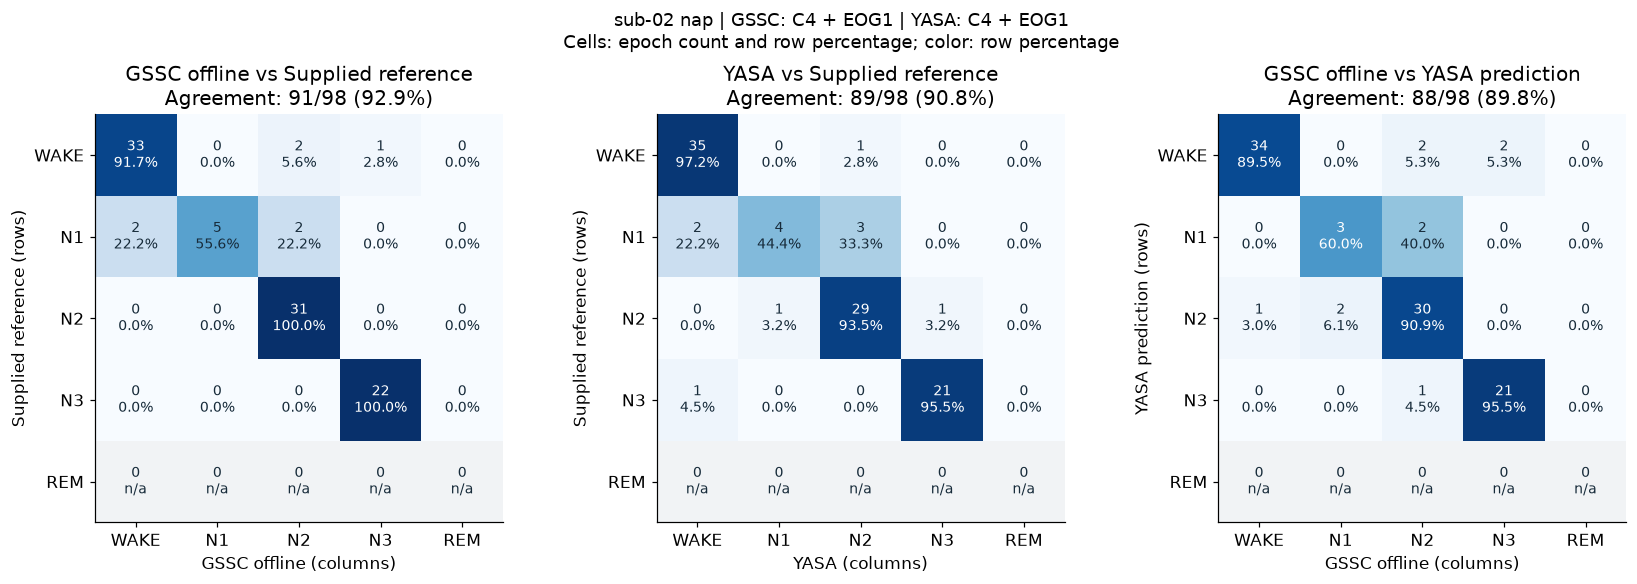

,Comparison,Matching_epochs,Total_epochs,Agreement_percent
0,GSSC offline vs reference,91,98,92.86
1,YASA vs reference,89,98,90.82
2,GSSC offline vs YASA,88,98,89.80


In [11]:
YASA_CSV = OUT / "yasa_c4_eog1/staging_predictions.csv"
YASA_CHOICES = YASA_CSV.with_name("analysis_choices.json")
# Restore the bundled two-channel YASA teaching export when no local export exists.
# Both the original predictions and their provenance are embedded in this notebook.
if not YASA_CSV.is_file() and not YASA_CHOICES.is_file():
    YASA_CSV.parent.mkdir(parents=True, exist_ok=True)
    YASA_CSV.write_text(_bundled_yasa_csv)
    YASA_CHOICES.write_text(json.dumps(_bundled_yasa_choices, indent=2))
    print("Restored the saved YASA C4 + EOG1 predictions embedded in this notebook.")
elif not YASA_CSV.is_file() or not YASA_CHOICES.is_file():
    raise RuntimeError("Incomplete YASA comparison export. Run the optional two-channel export cell in notebook 01.")
yasa_comparison, yasa_choices = load_yasa_comparison(
    YASA_CSV, YASA_CHOICES, table.Epoch.to_numpy(), start_seconds, reference
)
comparison_table = pd.DataFrame({
    "Epoch": table.Epoch, "Start_s": start_seconds, "Reference": reference,
    "GSSC_offline": predicted,
})
recorded_panels = [("Supplied reference", reference, "GSSC offline", predicted)]
comparison_metrics = [{"Comparison": "GSSC offline vs reference", "Matching_epochs": int(np.sum(reference == predicted)),
                       "Total_epochs": len(reference), "Agreement_percent": 100 * agreement}]
if yasa_comparison is not None:
    yasa_predicted = yasa_comparison.Predicted.to_numpy()
    comparison_table["YASA"] = yasa_predicted
    recorded_panels += [("Supplied reference", reference, "YASA", yasa_predicted),
                        ("YASA prediction", yasa_predicted, "GSSC offline", predicted)]
    for name, left, right in [("YASA vs reference", reference, yasa_predicted),
                              ("GSSC offline vs YASA", yasa_predicted, predicted)]:
        matches = int(np.sum(left == right))
        comparison_metrics.append({"Comparison": name, "Matching_epochs": matches,
                                   "Total_epochs": len(reference), "Agreement_percent": 100 * matches / len(reference)})
    print("YASA inputs:", yasa_choices["inputs"], "| GSSC inputs: C4, EOG1")
    disagreements = comparison_table.loc[comparison_table.GSSC_offline != comparison_table.YASA]
    disagreements.to_csv(OUT / "gssc_yasa_disagreements.csv", index=False)
    print(f"GSSC and YASA disagree on {len(disagreements)}/{len(reference)} epochs.")
    display(disagreements)
comparison_note = "sub-02 nap | GSSC: C4 + EOG1"
if yasa_comparison is not None:
    comparison_note += " | YASA: " + " + ".join(yasa_choices["inputs"])
recorded_confusions = plot_confusion_panels(
    recorded_panels, OUT / "04_recorded_confusion_matrices.png", note=comparison_note
)
comparison_table.to_csv(OUT / "classifier_comparison.csv", index=False)
pd.DataFrame(comparison_metrics).to_csv(OUT / "classifier_agreement.csv", index=False)
display(pd.DataFrame(comparison_metrics).round(2))

## Optional extension: epoch-by-epoch replay
This section uses the author's documented `ArrayInfer` API. It processes a
completed epoch, then passes the returned `hidden` state to the next call.
Inputs are float32 tensors shaped **(1, 1, 2560)**: one 30-second signal.

The helper processes only current/past data, using a stateful 0.3–30 Hz IIR
filter, resampling each completed epoch, and running channel normalization.
These are **illustrative streaming adaptations**, not the publication's
validated preprocessing.The bundled recurrent model was not separately trained here for causal use.
It remains bidirectional internally, but a call receives just one epoch and
the carried state, so no future epoch is supplied. This differs from the
full-sequence bidirectional pass above and from a separately trained forward GRU.
`ArrayInfer.infer` returns contextual logits, context-free logits, and hidden.
We use the FIRST output. Passing `hidden` preserves history; setting it to None
at every call resets recurrent history, but does not select the context-free head.

**Where is the GRU called?** Both marked `.infer(...)` calls (the demo
below and the loop inside `replay_epochs` in cell 8a) enter `ArrayInfer.infer`.
Internally it calls `self.con_net(reps, hidden)` for the single completed epoch.
This is the **forward / preceding-context inference condition**: epoch t uses
the current epoch and carried history, with no following epochs supplied.
The checkpoint still has a bidirectional GRU; these calls do not change its
architecture to a unidirectional GRU. The second returned output is context-free.


In [12]:
"""Teaching helpers for past/current-data-only GSSC replay; no device control.

These preprocessing choices are an illustrative adaptation, not the publication's
validated whole-record preprocessing. Validate them before a research deployment.
"""

from fractions import Fraction
from time import perf_counter

import numpy as np
import pandas as pd
from scipy import signal
import torch
from gssc.infer import ArrayInfer

STAGE_NAMES = np.array(["WAKE", "N1", "N2", "N3", "REM"])


class ReplayPreprocessor:
    """Stateful filter and running normalization using acquired samples only.

    Each call accepts ONE completed 30-second epoch, in volts, shaped
    (channels, samples). The output has 2560 samples per channel. The IIR filter
    retains its state; resampling uses only the completed epoch. Running channel
    mean/SD include the current and previous completed epochs. This differs from
    the original full-record, zero-phase filtering and normalization.
    """

    def __init__(self, sf, n_channels):
        self.samples_per_epoch = int(round(30 * sf))
        if sf <= 60 or not np.isclose(self.samples_per_epoch, 30 * sf):
            raise ValueError("Replay expects >60 Hz and an integer number of samples per 30 s.")
        self.n_channels = n_channels
        self.sos = signal.butter(4, [0.3, 30], btype="bandpass", fs=sf, output="sos")
        self.filter_state = None
        self.count = 0
        self.mean = np.zeros(n_channels)
        self.m2 = np.zeros(n_channels)
        self.ratio = Fraction(2560, self.samples_per_epoch)

    def process(self, chunk_v):
        chunk = np.asarray(chunk_v, dtype=np.float64) * 1e6  # V -> microvolts
        if chunk.shape != (self.n_channels, self.samples_per_epoch):
            raise ValueError("Supply exactly one complete 30-second epoch per call.")
        if not np.isfinite(chunk).all() or np.any(chunk.std(axis=1) < 1e-8):
            raise ValueError("Non-finite or flat channel: interrupt the replay and inspect it.")
        if self.filter_state is None:
            self.filter_state = np.array([
                signal.sosfilt_zi(self.sos) * channel[0] for channel in chunk
            ])
        filtered = np.empty_like(chunk)
        for channel in range(self.n_channels):
            filtered[channel], self.filter_state[channel] = signal.sosfilt(
                self.sos, chunk[channel], zi=self.filter_state[channel]
            )
        resampled = signal.resample_poly(
            filtered, self.ratio.numerator, self.ratio.denominator, axis=1
        )
        assert resampled.shape == (self.n_channels, 2560)

        # Merge this epoch's statistics with those of the observed history.
        batch_count = resampled.shape[1]
        batch_mean = resampled.mean(axis=1)
        batch_m2 = ((resampled - batch_mean[:, None]) ** 2).sum(axis=1)
        total = self.count + batch_count
        delta = batch_mean - self.mean
        self.m2 += batch_m2 + delta**2 * self.count * batch_count / total
        self.mean += delta * batch_count / total
        self.count = total
        sd = np.sqrt(self.m2 / self.count)
        if np.any(sd < 1e-8):
            raise ValueError("Channel variance is too small for normalization.")
        return ((resampled - self.mean[:, None]) / sd[:, None]).astype(np.float32)


def replay_epochs(raw, eeg_name="C4", eog_name="EOG1", max_epochs=None):
    """Process recorded epochs in order without reading future samples.

    The loop runs faster than wall-clock time: there is no 30-second sleep.
    Epoch_end_s is the source-data availability time. Processing_s measures only
    preprocessing + model execution, excluding acquisition/transport/control.
    A fresh preprocessor, model and hidden state are created for each recording.
    Finite/flat checks are not a validated artifact or arousal detector.
    """
    channels = [eeg_name] + ([eog_name] if eog_name is not None else [])
    sf = float(raw.info["sfreq"])
    samples = int(round(sf * 30))
    n_epochs = raw.n_times // samples
    if max_epochs is not None:
        n_epochs = min(n_epochs, int(max_epochs))
    if n_epochs < 1:
        raise ValueError("At least one complete 30-second epoch is required.")
    preprocessor = ReplayPreprocessor(sf, len(channels))
    model = ArrayInfer(use_cuda=False)  # Loads models; no GRU inference yet.
    hidden = None  # Reset GRU history once at the START of this recording.
    rows = []
    for epoch in range(n_epochs):
        start, stop = epoch * samples, (epoch + 1) * samples
        started = perf_counter()
        prepared = preprocessor.process(raw.get_data(picks=channels, start=start, stop=stop))
        sigs = {"eeg": torch.from_numpy(prepared[0:1, None, :])}
        if eog_name is not None:
            sigs["eog"] = torch.from_numpy(prepared[1:2, None, :])
        # GRU call via this wrapper: FORWARD / PRECEDING-CONTEXT inference condition.
        # ArrayInfer.infer calls: logits, hidden = self.con_net(reps, hidden).
        # Only the current completed epoch is supplied; hidden carries earlier context.
        # The checkpoint remains bidirectional internally; no future epoch is supplied.
        # First output uses the GRU; the discarded second is the context-free head.
        logits, _, hidden = model.infer(sigs, hidden=hidden)
        # Keep hidden for the NEXT epoch; classify from this epoch's contextual logits.
        probabilities = torch.softmax(logits, dim=-1).cpu().numpy()[0]
        elapsed = perf_counter() - started
        if not np.isfinite(probabilities).all() or not torch.isfinite(hidden).all():
            raise RuntimeError("Non-finite model output: interrupt and inspect the input.")
        rows.append({
            "Epoch": epoch, "Start_s": epoch * 30, "Epoch_end_s": (epoch + 1) * 30,
            "Predicted": STAGE_NAMES[probabilities.argmax()],
            "Max_probability": float(probabilities.max()), "Processing_s": elapsed,
            **{f"P_{stage}": float(p) for stage, p in zip(STAGE_NAMES, probabilities)},
        })
    return pd.DataFrame(rows)


def illustrate_eligibility(table, probability_cutoff=0.8, stable_epochs=2):
    """Add illustrative N2/N3 eligibility labels; this sends no commands.

    Cutoff and stability count are teaching choices, not a validated protocol.
    There is no real-time signal-quality or arousal monitor in this exercise.
    """
    if not 0 <= probability_cutoff <= 1 or int(stable_epochs) != stable_epochs or stable_epochs < 1:
        raise ValueError("Use a probability in [0,1] and a positive integer stability count.")
    result = table.copy()
    result["P_N2_or_N3"] = result["P_N2"] + result["P_N3"]
    candidate = result.Predicted.isin(["N2", "N3"]) & (
        result.P_N2_or_N3 >= probability_cutoff
    )
    count = 0
    labels = []
    for eligible in candidate:
        count = count + 1 if eligible else 0
        labels.append("ELIGIBLE" if count >= stable_epochs else "HOLD")
    result["Demo_eligibility"] = labels
    return result

In [13]:
from gssc.infer import ArrayInfer

sequential_model = ArrayInfer(use_cuda=False)  # Loads models; no GRU inference yet.
preprocessor = ReplayPreprocessor(sf, n_channels=2)
hidden = None  # Reset GRU history at the START of a recording, outside the loop.
for epoch in range(2):
    start, stop = int(epoch * 30 * sf), int((epoch + 1) * 30 * sf)
    acquired = raw.get_data(picks=["C4", "EOG1"], start=start, stop=stop)
    prepared = preprocessor.process(acquired)
    sigs = {"eeg": torch.from_numpy(prepared[0:1, None, :]),
            "eog": torch.from_numpy(prepared[1:2, None, :])}
    # GRU call via this wrapper: FORWARD / PRECEDING-CONTEXT inference condition.
    # Internally: logits, hidden = self.con_net(reps, hidden).
    # sigs contains ONLY this completed epoch; hidden carries earlier context.
    # The GRU checkpoint remains bidirectional internally; no future epoch is supplied.
    logits, context_free_logits, hidden = sequential_model.infer(sigs, hidden=hidden)
    # Use contextual logits for the prediction; retain hidden for the NEXT epoch.
    # context_free_logits is a separate head and is not used for this prediction.
    print(f"Epoch {epoch}:", STAGE_NAMES[int(logits.argmax(dim=-1).item())])
# The second call receives the first call's hidden state.

Epoch 0: WAKE
Epoch 1: WAKE


In [14]:
RUN_REPLAY = True  # Set False to skip the full replay and eligibility exercise.
if RUN_REPLAY:
    # FORWARD / PRECEDING-CONTEXT inference for the full replay.
    # This wrapper calls model.infer(...) once per epoch in cell 8a's helper loop;
    # each new replay starts with fresh GRU history and preprocessing state.
    replay_table = replay_epochs(raw, eeg_name="C4", eog_name="EOG1")
    replay_table["Reference"] = reference[:len(replay_table)]
    replay_table.to_csv(OUT / "gssc_sequential_replay.csv", index=False)
    print("Epochs processed sequentially:", len(replay_table))
    print(f"Median preprocessing + inference: {replay_table.Processing_s.median():.3f} s/epoch")
    print("This excludes acquisition, stream buffering and device-command latency.")
    display(replay_table.head().round(3))

Epochs processed sequentially: 98
Median preprocessing + inference: 0.007 s/epoch
This excludes acquisition, stream buffering and device-command latency.


,Epoch,Start_s,Epoch_end_s,Predicted,Max_probability,Processing_s,P_WAKE,P_N1,P_N2,P_N3,P_REM,Reference
0,0,0,30,WAKE,0.960,0.008,0.960,0.000,0.006,0.034,0.0,WAKE
1,1,30,60,WAKE,0.992,0.007,0.992,0.000,0.004,0.004,0.0,WAKE
2,2,60,90,WAKE,0.998,0.007,0.998,0.000,0.001,0.000,0.0,WAKE
3,3,90,120,WAKE,0.998,0.007,0.998,0.001,0.001,0.000,0.0,WAKE
4,4,120,150,WAKE,0.998,0.007,0.998,0.001,0.001,0.000,0.0,WAKE


## Illustrate N2/N3 eligibility
We label epochs as ELIGIBLE or HOLD using N2/N3 probability and a run of stable
epochs. The values below are **teaching choices**, not a stimulation protocol.
No stimulation occurs. This is not an arousal or signal-quality detector.

**Try:** change `stable_epochs` from 2 to 3. Does eligibility begin later?
Changing this rule does not change GSSC predictions.

In [15]:
if RUN_REPLAY:
    stable_epochs = 2  # CHANGE ME to 3.
    demo_log = illustrate_eligibility(replay_table, probability_cutoff=0.8,
                                     stable_epochs=stable_epochs)
    demo_log.to_csv(OUT / "demo_n2_n3_eligibility.csv", index=False)
    display(demo_log[["Epoch", "Epoch_end_s", "Predicted", "P_N2_or_N3", "Demo_eligibility"]])
    print("ELIGIBLE epochs:", int((demo_log.Demo_eligibility == "ELIGIBLE").sum()))
    print("Saved an eligibility log only; no device is connected.")
    summary["replay"] = {
        "n_epochs": len(replay_table), "preprocessing": "past/current-only IIR + running normalization",
        "median_processing_s": float(replay_table.Processing_s.median()),
        "illustrative_eligibility_cutoff": 0.8, "illustrative_stable_epochs": stable_epochs,
        "hardware_connected": False,
    }
    (OUT / "run_summary.json").write_text(json.dumps(summary, indent=2))

,Epoch,Epoch_end_s,Predicted,P_N2_or_N3,Demo_eligibility
0,0,30,WAKE,0.039840,HOLD
1,1,60,WAKE,0.007419,HOLD
2,2,90,WAKE,0.001544,HOLD
3,3,120,WAKE,0.000911,HOLD
4,4,150,WAKE,0.000717,HOLD
...,...,...,...,...,...
93,93,2820,WAKE,0.042307,HOLD
94,94,2850,WAKE,0.030503,HOLD
95,95,2880,WAKE,0.029478,HOLD
96,96,2910,WAKE,0.019432,HOLD


ELIGIBLE epochs: 41
Saved an eligibility log only; no device is connected.


## Replay versus reference and offline GSSC
Both context availability and preprocessing change between offline and replay.
These matrices cannot isolate the effect of direction alone. Equal overall
agreement percentages can also hide different errors on individual epochs.

A dedicated full-record-versus-replay matrix is also saved as figure 06: rows are full-record predictions and columns are replay predictions. Off-diagonal cells show disagreements. The accompanying table lists the affected epochs. This measures agreement between modes, not accuracy against a scorer.

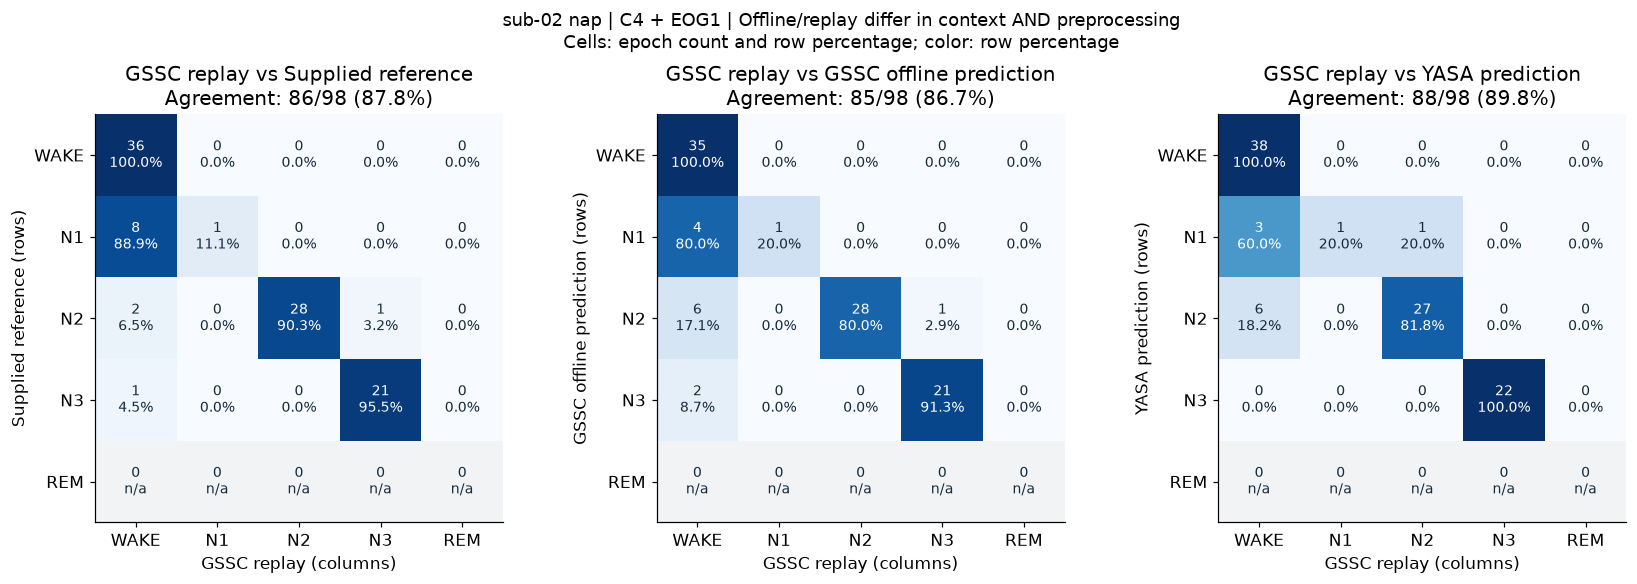

,Comparison,Matching_epochs,Total_epochs,Agreement_percent
0,GSSC offline vs reference,91,98,92.86
1,YASA vs reference,89,98,90.82
2,GSSC offline vs YASA,88,98,89.80
3,GSSC replay vs reference,86,98,87.76
4,GSSC replay vs offline,85,98,86.73
5,GSSC replay vs YASA,88,98,89.80


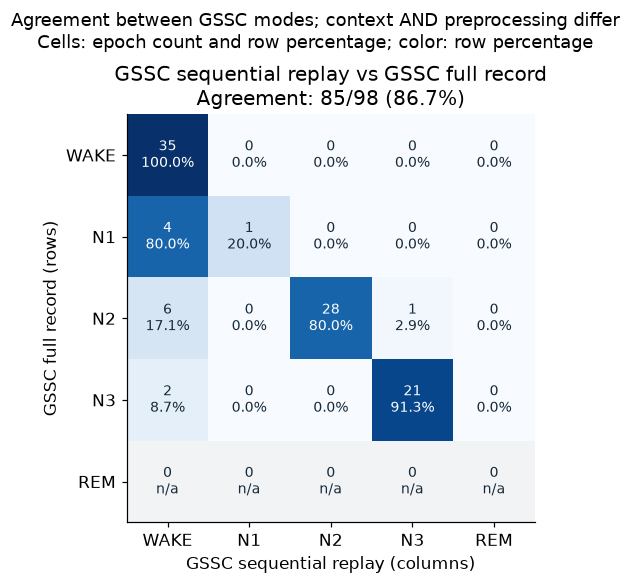

Full record and replay disagree on 13/98 epochs.


,Epoch,Start_s,Reference,GSSC_offline,GSSC_replay
28,28,840,N1,N1,WAKE
29,29,870,N1,N1,WAKE
32,32,960,N1,N1,WAKE
33,33,990,N1,N1,WAKE
34,34,1020,N1,N2,WAKE
35,35,1050,N1,N2,WAKE
36,36,1080,N2,N2,WAKE
37,37,1110,N2,N2,WAKE
68,68,2040,N2,N2,N3
90,90,2700,N3,N3,WAKE


In [16]:
if RUN_REPLAY:
    assert np.array_equal(replay_table.Epoch.to_numpy(), table.Epoch.to_numpy())
    assert np.allclose(replay_table.Start_s, start_seconds)
    assert np.array_equal(replay_table.Reference.to_numpy(), reference)
    replay_predicted = replay_table.Predicted.to_numpy()
    replay_panels = [("Supplied reference", reference, "GSSC replay", replay_predicted),
                     ("GSSC offline prediction", predicted, "GSSC replay", replay_predicted)]
    if yasa_comparison is not None:
        replay_panels.append(("YASA prediction", yasa_predicted, "GSSC replay", replay_predicted))
    replay_confusions = plot_confusion_panels(
        replay_panels, OUT / "05_replay_confusion_matrices.png",
        note="sub-02 nap | C4 + EOG1 | Offline/replay differ in context AND preprocessing"
    )
    comparison_table["GSSC_replay"] = replay_predicted
    comparison_table.to_csv(OUT / "classifier_comparison.csv", index=False)
    replay_comparisons = [("GSSC replay vs reference", reference), ("GSSC replay vs offline", predicted)]
    if yasa_comparison is not None:
        replay_comparisons.append(("GSSC replay vs YASA", yasa_predicted))
    for name, left in replay_comparisons:
        matches = int(np.sum(left == replay_predicted))
        comparison_metrics.append({"Comparison": name, "Matching_epochs": matches,
                                   "Total_epochs": len(reference), "Agreement_percent": 100 * matches / len(reference)})
    pd.DataFrame(comparison_metrics).to_csv(OUT / "classifier_agreement.csv", index=False)
    display(pd.DataFrame(comparison_metrics).round(2))
    # Dedicated full-record/replay matrix: rows = full record, columns = replay.
    full_record_replay_confusion = plot_confusion_panels(
        [("GSSC full record", predicted, "GSSC sequential replay", replay_predicted)],
        OUT / "06_full_record_vs_sequential_replay.png",
        note="Agreement between GSSC modes; context AND preprocessing differ"
    )[0]
    replay_disagreements = comparison_table.loc[
        comparison_table.GSSC_offline != comparison_table.GSSC_replay,
        ["Epoch", "Start_s", "Reference", "GSSC_offline", "GSSC_replay"]
    ].copy()
    replay_disagreements.to_csv(OUT / "full_record_replay_disagreements.csv", index=False)
    print(f"Full record and replay disagree on {len(replay_disagreements)}/{len(reference)} epochs.")
    display(replay_disagreements)


## Take home
* GSSC classifies epochs; YASA can measure events in the recorded EEG offline.
* A model probability is not measured accuracy for that epoch.
* Record-based preprocessing and sequential preprocessing can yield different results.
* Validate nap staging and TIS-contaminated EEG before using predictions for control.

**Sources:** Hanna & Floel (2023), DOI 10.3389/fninf.2023.1086634;
https://github.com/jshanna100/gssc (AGPL-3.0).
Data: Vallat & Mallett, YASA sample dataset v1, Zenodo record 14564285.

## Upstream software license notice

GSSC retains its upstream license. The notice is reproduced here so this notebook does not depend on a separate license file.

```text
GNU Affero General Public License
=================================

_Version 3, 19 November 2007_
_Copyright © 2007 Free Software Foundation, Inc. &lt;<http://fsf.org/>&gt;_

Everyone is permitted to copy and distribute verbatim copies
of this license document, but changing it is not allowed.

## Preamble

The GNU Affero General Public License is a free, copyleft license for
software and other kinds of works, specifically designed to ensure
cooperation with the community in the case of network server software.

The licenses for most software and other practical works are designed
to take away your freedom to share and change the works.  By contrast,
our General Public Licenses are intended to guarantee your freedom to
share and change all versions of a program--to make sure it remains free
software for all its users.

When we speak of free software, we are referring to freedom, not
price.  Our General Public Licenses are designed to make sure that you
have the freedom to distribute copies of free software (and charge for
them if you wish), that you receive source code or can get it if you
want it, that you can change the software or use pieces of it in new
free programs, and that you know you can do these things.

Developers that use our General Public Licenses protect your rights
with two steps: **(1)** assert copyright on the software, and **(2)** offer
you this License which gives you legal permission to copy, distribute
and/or modify the software.

A secondary benefit of defending all users' freedom is that
improvements made in alternate versions of the program, if they
receive widespread use, become available for other developers to
incorporate.  Many developers of free software are heartened and
encouraged by the resulting cooperation.  However, in the case of
software used on network servers, this result may fail to come about.
The GNU General Public License permits making a modified version and
letting the public access it on a server without ever releasing its
source code to the public.

The GNU Affero General Public License is designed specifically to
ensure that, in such cases, the modified source code becomes available
to the community.  It requires the operator of a network server to
provide the source code of the modified version running there to the
users of that server.  Therefore, public use of a modified version, on
a publicly accessible server, gives the public access to the source
code of the modified version.

An older license, called the Affero General Public License and
published by Affero, was designed to accomplish similar goals.  This is
a different license, not a version of the Affero GPL, but Affero has
released a new version of the Affero GPL which permits relicensing under
this license.

The precise terms and conditions for copying, distribution and
modification follow.

## TERMS AND CONDITIONS

### 0. Definitions

“This License” refers to version 3 of the GNU Affero General Public License.

“Copyright” also means copyright-like laws that apply to other kinds of
works, such as semiconductor masks.

“The Program” refers to any copyrightable work licensed under this
License.  Each licensee is addressed as “you”.  “Licensees” and
“recipients” may be individuals or organizations.

To “modify” a work means to copy from or adapt all or part of the work
in a fashion requiring copyright permission, other than the making of an
exact copy.  The resulting work is called a “modified version” of the
earlier work or a work “based on” the earlier work.

A “covered work” means either the unmodified Program or a work based
on the Program.

To “propagate” a work means to do anything with it that, without
permission, would make you directly or secondarily liable for
infringement under applicable copyright law, except executing it on a
computer or modifying a private copy.  Propagation includes copying,
distribution (with or without modification), making available to the
public, and in some countries other activities as well.

To “convey” a work means any kind of propagation that enables other
parties to make or receive copies.  Mere interaction with a user through
a computer network, with no transfer of a copy, is not conveying.

An interactive user interface displays “Appropriate Legal Notices”
to the extent that it includes a convenient and prominently visible
feature that **(1)** displays an appropriate copyright notice, and **(2)**
tells the user that there is no warranty for the work (except to the
extent that warranties are provided), that licensees may convey the
work under this License, and how to view a copy of this License.  If
the interface presents a list of user commands or options, such as a
menu, a prominent item in the list meets this criterion.

### 1. Source Code

The “source code” for a work means the preferred form of the work
for making modifications to it.  “Object code” means any non-source
form of a work.

A “Standard Interface” means an interface that either is an official
standard defined by a recognized standards body, or, in the case of
interfaces specified for a particular programming language, one that
is widely used among developers working in that language.

The “System Libraries” of an executable work include anything, other
than the work as a whole, that **(a)** is included in the normal form of
packaging a Major Component, but which is not part of that Major
Component, and **(b)** serves only to enable use of the work with that
Major Component, or to implement a Standard Interface for which an
implementation is available to the public in source code form.  A
“Major Component”, in this context, means a major essential component
(kernel, window system, and so on) of the specific operating system
(if any) on which the executable work runs, or a compiler used to
produce the work, or an object code interpreter used to run it.

The “Corresponding Source” for a work in object code form means all
the source code needed to generate, install, and (for an executable
work) run the object code and to modify the work, including scripts to
control those activities.  However, it does not include the work's
System Libraries, or general-purpose tools or generally available free
programs which are used unmodified in performing those activities but
which are not part of the work.  For example, Corresponding Source
includes interface definition files associated with source files for
the work, and the source code for shared libraries and dynamically
linked subprograms that the work is specifically designed to require,
such as by intimate data communication or control flow between those
subprograms and other parts of the work.

The Corresponding Source need not include anything that users
can regenerate automatically from other parts of the Corresponding
Source.

The Corresponding Source for a work in source code form is that
same work.

### 2. Basic Permissions

All rights granted under this License are granted for the term of
copyright on the Program, and are irrevocable provided the stated
conditions are met.  This License explicitly affirms your unlimited
permission to run the unmodified Program.  The output from running a
covered work is covered by this License only if the output, given its
content, constitutes a covered work.  This License acknowledges your
rights of fair use or other equivalent, as provided by copyright law.

You may make, run and propagate covered works that you do not
convey, without conditions so long as your license otherwise remains
in force.  You may convey covered works to others for the sole purpose
of having them make modifications exclusively for you, or provide you
with facilities for running those works, provided that you comply with
the terms of this License in conveying all material for which you do
not control copyright.  Those thus making or running the covered works
for you must do so exclusively on your behalf, under your direction
and control, on terms that prohibit them from making any copies of
your copyrighted material outside their relationship with you.

Conveying under any other circumstances is permitted solely under
the conditions stated below.  Sublicensing is not allowed; section 10
makes it unnecessary.

### 3. Protecting Users' Legal Rights From Anti-Circumvention Law

No covered work shall be deemed part of an effective technological
measure under any applicable law fulfilling obligations under article
11 of the WIPO copyright treaty adopted on 20 December 1996, or
similar laws prohibiting or restricting circumvention of such
measures.

When you convey a covered work, you waive any legal power to forbid
circumvention of technological measures to the extent such circumvention
is effected by exercising rights under this License with respect to
the covered work, and you disclaim any intention to limit operation or
modification of the work as a means of enforcing, against the work's
users, your or third parties' legal rights to forbid circumvention of
technological measures.

### 4. Conveying Verbatim Copies

You may convey verbatim copies of the Program's source code as you
receive it, in any medium, provided that you conspicuously and
appropriately publish on each copy an appropriate copyright notice;
keep intact all notices stating that this License and any
non-permissive terms added in accord with section 7 apply to the code;
keep intact all notices of the absence of any warranty; and give all
recipients a copy of this License along with the Program.

You may charge any price or no price for each copy that you convey,
and you may offer support or warranty protection for a fee.

### 5. Conveying Modified Source Versions

You may convey a work based on the Program, or the modifications to
produce it from the Program, in the form of source code under the
terms of section 4, provided that you also meet all of these conditions:

* **a)** The work must carry prominent notices stating that you modified
it, and giving a relevant date.
* **b)** The work must carry prominent notices stating that it is
released under this License and any conditions added under section 7.
This requirement modifies the requirement in section 4 to
“keep intact all notices”.
* **c)** You must license the entire work, as a whole, under this
License to anyone who comes into possession of a copy.  This
License will therefore apply, along with any applicable section 7
additional terms, to the whole of the work, and all its parts,
regardless of how they are packaged.  This License gives no
permission to license the work in any other way, but it does not
invalidate such permission if you have separately received it.
* **d)** If the work has interactive user interfaces, each must display
Appropriate Legal Notices; however, if the Program has interactive
interfaces that do not display Appropriate Legal Notices, your
work need not make them do so.

A compilation of a covered work with other separate and independent
works, which are not by their nature extensions of the covered work,
and which are not combined with it such as to form a larger program,
in or on a volume of a storage or distribution medium, is called an
“aggregate” if the compilation and its resulting copyright are not
used to limit the access or legal rights of the compilation's users
beyond what the individual works permit.  Inclusion of a covered work
in an aggregate does not cause this License to apply to the other
parts of the aggregate.

### 6. Conveying Non-Source Forms

You may convey a covered work in object code form under the terms
of sections 4 and 5, provided that you also convey the
machine-readable Corresponding Source under the terms of this License,
in one of these ways:

* **a)** Convey the object code in, or embodied in, a physical product
(including a physical distribution medium), accompanied by the
Corresponding Source fixed on a durable physical medium
customarily used for software interchange.
* **b)** Convey the object code in, or embodied in, a physical product
(including a physical distribution medium), accompanied by a
written offer, valid for at least three years and valid for as
long as you offer spare parts or customer support for that product
model, to give anyone who possesses the object code either **(1)** a
copy of the Corresponding Source for all the software in the
product that is covered by this License, on a durable physical
medium customarily used for software interchange, for a price no
more than your reasonable cost of physically performing this
conveying of source, or **(2)** access to copy the
Corresponding Source from a network server at no charge.
* **c)** Convey individual copies of the object code with a copy of the
written offer to provide the Corresponding Source.  This
alternative is allowed only occasionally and noncommercially, and
only if you received the object code with such an offer, in accord
with subsection 6b.
* **d)** Convey the object code by offering access from a designated
place (gratis or for a charge), and offer equivalent access to the
Corresponding Source in the same way through the same place at no
further charge.  You need not require recipients to copy the
Corresponding Source along with the object code.  If the place to
copy the object code is a network server, the Corresponding Source
may be on a different server (operated by you or a third party)
that supports equivalent copying facilities, provided you maintain
clear directions next to the object code saying where to find the
Corresponding Source.  Regardless of what server hosts the
Corresponding Source, you remain obligated to ensure that it is
available for as long as needed to satisfy these requirements.
* **e)** Convey the object code using peer-to-peer transmission, provided
you inform other peers where the object code and Corresponding
Source of the work are being offered to the general public at no
charge under subsection 6d.

A separable portion of the object code, whose source code is excluded
from the Corresponding Source as a System Library, need not be
included in conveying the object code work.

A “User Product” is either **(1)** a “consumer product”, which means any
tangible personal property which is normally used for personal, family,
or household purposes, or **(2)** anything designed or sold for incorporation
into a dwelling.  In determining whether a product is a consumer product,
doubtful cases shall be resolved in favor of coverage.  For a particular
product received by a particular user, “normally used” refers to a
typical or common use of that class of product, regardless of the status
of the particular user or of the way in which the particular user
actually uses, or expects or is expected to use, the product.  A product
is a consumer product regardless of whether the product has substantial
commercial, industrial or non-consumer uses, unless such uses represent
the only significant mode of use of the product.

“Installation Information” for a User Product means any methods,
procedures, authorization keys, or other information required to install
and execute modified versions of a covered work in that User Product from
a modified version of its Corresponding Source.  The information must
suffice to ensure that the continued functioning of the modified object
code is in no case prevented or interfered with solely because
modification has been made.

If you convey an object code work under this section in, or with, or
specifically for use in, a User Product, and the conveying occurs as
part of a transaction in which the right of possession and use of the
User Product is transferred to the recipient in perpetuity or for a
fixed term (regardless of how the transaction is characterized), the
Corresponding Source conveyed under this section must be accompanied
by the Installation Information.  But this requirement does not apply
if neither you nor any third party retains the ability to install
modified object code on the User Product (for example, the work has
been installed in ROM).

The requirement to provide Installation Information does not include a
requirement to continue to provide support service, warranty, or updates
for a work that has been modified or installed by the recipient, or for
the User Product in which it has been modified or installed.  Access to a
network may be denied when the modification itself materially and
adversely affects the operation of the network or violates the rules and
protocols for communication across the network.

Corresponding Source conveyed, and Installation Information provided,
in accord with this section must be in a format that is publicly
documented (and with an implementation available to the public in
source code form), and must require no special password or key for
unpacking, reading or copying.

### 7. Additional Terms

“Additional permissions” are terms that supplement the terms of this
License by making exceptions from one or more of its conditions.
Additional permissions that are applicable to the entire Program shall
be treated as though they were included in this License, to the extent
that they are valid under applicable law.  If additional permissions
apply only to part of the Program, that part may be used separately
under those permissions, but the entire Program remains governed by
this License without regard to the additional permissions.

When you convey a copy of a covered work, you may at your option
remove any additional permissions from that copy, or from any part of
it.  (Additional permissions may be written to require their own
removal in certain cases when you modify the work.)  You may place
additional permissions on material, added by you to a covered work,
for which you have or can give appropriate copyright permission.

Notwithstanding any other provision of this License, for material you
add to a covered work, you may (if authorized by the copyright holders of
that material) supplement the terms of this License with terms:

* **a)** Disclaiming warranty or limiting liability differently from the
terms of sections 15 and 16 of this License; or
* **b)** Requiring preservation of specified reasonable legal notices or
author attributions in that material or in the Appropriate Legal
Notices displayed by works containing it; or
* **c)** Prohibiting misrepresentation of the origin of that material, or
requiring that modified versions of such material be marked in
reasonable ways as different from the original version; or
* **d)** Limiting the use for publicity purposes of names of licensors or
authors of the material; or
* **e)** Declining to grant rights under trademark law for use of some
trade names, trademarks, or service marks; or
* **f)** Requiring indemnification of licensors and authors of that
material by anyone who conveys the material (or modified versions of
it) with contractual assumptions of liability to the recipient, for
any liability that these contractual assumptions directly impose on
those licensors and authors.

All other non-permissive additional terms are considered “further
restrictions” within the meaning of section 10.  If the Program as you
received it, or any part of it, contains a notice stating that it is
governed by this License along with a term that is a further
restriction, you may remove that term.  If a license document contains
a further restriction but permits relicensing or conveying under this
License, you may add to a covered work material governed by the terms
of that license document, provided that the further restriction does
not survive such relicensing or conveying.

If you add terms to a covered work in accord with this section, you
must place, in the relevant source files, a statement of the
additional terms that apply to those files, or a notice indicating
where to find the applicable terms.

Additional terms, permissive or non-permissive, may be stated in the
form of a separately written license, or stated as exceptions;
the above requirements apply either way.

### 8. Termination

You may not propagate or modify a covered work except as expressly
provided under this License.  Any attempt otherwise to propagate or
modify it is void, and will automatically terminate your rights under
this License (including any patent licenses granted under the third
paragraph of section 11).

However, if you cease all violation of this License, then your
license from a particular copyright holder is reinstated **(a)**
provisionally, unless and until the copyright holder explicitly and
finally terminates your license, and **(b)** permanently, if the copyright
holder fails to notify you of the violation by some reasonable means
prior to 60 days after the cessation.

Moreover, your license from a particular copyright holder is
reinstated permanently if the copyright holder notifies you of the
violation by some reasonable means, this is the first time you have
received notice of violation of this License (for any work) from that
copyright holder, and you cure the violation prior to 30 days after
your receipt of the notice.

Termination of your rights under this section does not terminate the
licenses of parties who have received copies or rights from you under
this License.  If your rights have been terminated and not permanently
reinstated, you do not qualify to receive new licenses for the same
material under section 10.

### 9. Acceptance Not Required for Having Copies

You are not required to accept this License in order to receive or
run a copy of the Program.  Ancillary propagation of a covered work
occurring solely as a consequence of using peer-to-peer transmission
to receive a copy likewise does not require acceptance.  However,
nothing other than this License grants you permission to propagate or
modify any covered work.  These actions infringe copyright if you do
not accept this License.  Therefore, by modifying or propagating a
covered work, you indicate your acceptance of this License to do so.

### 10. Automatic Licensing of Downstream Recipients

Each time you convey a covered work, the recipient automatically
receives a license from the original licensors, to run, modify and
propagate that work, subject to this License.  You are not responsible
for enforcing compliance by third parties with this License.

An “entity transaction” is a transaction transferring control of an
organization, or substantially all assets of one, or subdividing an
organization, or merging organizations.  If propagation of a covered
work results from an entity transaction, each party to that
transaction who receives a copy of the work also receives whatever
licenses to the work the party's predecessor in interest had or could
give under the previous paragraph, plus a right to possession of the
Corresponding Source of the work from the predecessor in interest, if
the predecessor has it or can get it with reasonable efforts.

You may not impose any further restrictions on the exercise of the
rights granted or affirmed under this License.  For example, you may
not impose a license fee, royalty, or other charge for exercise of
rights granted under this License, and you may not initiate litigation
(including a cross-claim or counterclaim in a lawsuit) alleging that
any patent claim is infringed by making, using, selling, offering for
sale, or importing the Program or any portion of it.

### 11. Patents

A “contributor” is a copyright holder who authorizes use under this
License of the Program or a work on which the Program is based.  The
work thus licensed is called the contributor's “contributor version”.

A contributor's “essential patent claims” are all patent claims
owned or controlled by the contributor, whether already acquired or
hereafter acquired, that would be infringed by some manner, permitted
by this License, of making, using, or selling its contributor version,
but do not include claims that would be infringed only as a
consequence of further modification of the contributor version.  For
purposes of this definition, “control” includes the right to grant
patent sublicenses in a manner consistent with the requirements of
this License.

Each contributor grants you a non-exclusive, worldwide, royalty-free
patent license under the contributor's essential patent claims, to
make, use, sell, offer for sale, import and otherwise run, modify and
propagate the contents of its contributor version.

In the following three paragraphs, a “patent license” is any express
agreement or commitment, however denominated, not to enforce a patent
(such as an express permission to practice a patent or covenant not to
sue for patent infringement).  To “grant” such a patent license to a
party means to make such an agreement or commitment not to enforce a
patent against the party.

If you convey a covered work, knowingly relying on a patent license,
and the Corresponding Source of the work is not available for anyone
to copy, free of charge and under the terms of this License, through a
publicly available network server or other readily accessible means,
then you must either **(1)** cause the Corresponding Source to be so
available, or **(2)** arrange to deprive yourself of the benefit of the
patent license for this particular work, or **(3)** arrange, in a manner
consistent with the requirements of this License, to extend the patent
license to downstream recipients.  “Knowingly relying” means you have
actual knowledge that, but for the patent license, your conveying the
covered work in a country, or your recipient's use of the covered work
in a country, would infringe one or more identifiable patents in that
country that you have reason to believe are valid.

If, pursuant to or in connection with a single transaction or
arrangement, you convey, or propagate by procuring conveyance of, a
covered work, and grant a patent license to some of the parties
receiving the covered work authorizing them to use, propagate, modify
or convey a specific copy of the covered work, then the patent license
you grant is automatically extended to all recipients of the covered
work and works based on it.

A patent license is “discriminatory” if it does not include within
the scope of its coverage, prohibits the exercise of, or is
conditioned on the non-exercise of one or more of the rights that are
specifically granted under this License.  You may not convey a covered
work if you are a party to an arrangement with a third party that is
in the business of distributing software, under which you make payment
to the third party based on the extent of your activity of conveying
the work, and under which the third party grants, to any of the
parties who would receive the covered work from you, a discriminatory
patent license **(a)** in connection with copies of the covered work
conveyed by you (or copies made from those copies), or **(b)** primarily
for and in connection with specific products or compilations that
contain the covered work, unless you entered into that arrangement,
or that patent license was granted, prior to 28 March 2007.

Nothing in this License shall be construed as excluding or limiting
any implied license or other defenses to infringement that may
otherwise be available to you under applicable patent law.

### 12. No Surrender of Others' Freedom

If conditions are imposed on you (whether by court order, agreement or
otherwise) that contradict the conditions of this License, they do not
excuse you from the conditions of this License.  If you cannot convey a
covered work so as to satisfy simultaneously your obligations under this
License and any other pertinent obligations, then as a consequence you may
not convey it at all.  For example, if you agree to terms that obligate you
to collect a royalty for further conveying from those to whom you convey
the Program, the only way you could satisfy both those terms and this
License would be to refrain entirely from conveying the Program.

### 13. Remote Network Interaction; Use with the GNU General Public License

Notwithstanding any other provision of this License, if you modify the
Program, your modified version must prominently offer all users
interacting with it remotely through a computer network (if your version
supports such interaction) an opportunity to receive the Corresponding
Source of your version by providing access to the Corresponding Source
from a network server at no charge, through some standard or customary
means of facilitating copying of software.  This Corresponding Source
shall include the Corresponding Source for any work covered by version 3
of the GNU General Public License that is incorporated pursuant to the
following paragraph.

Notwithstanding any other provision of this License, you have
permission to link or combine any covered work with a work licensed
under version 3 of the GNU General Public License into a single
combined work, and to convey the resulting work.  The terms of this
License will continue to apply to the part which is the covered work,
but the work with which it is combined will remain governed by version
3 of the GNU General Public License.

### 14. Revised Versions of this License

The Free Software Foundation may publish revised and/or new versions of
the GNU Affero General Public License from time to time.  Such new versions
will be similar in spirit to the present version, but may differ in detail to
address new problems or concerns.

Each version is given a distinguishing version number.  If the
Program specifies that a certain numbered version of the GNU Affero General
Public License “or any later version” applies to it, you have the
option of following the terms and conditions either of that numbered
version or of any later version published by the Free Software
Foundation.  If the Program does not specify a version number of the
GNU Affero General Public License, you may choose any version ever published
by the Free Software Foundation.

If the Program specifies that a proxy can decide which future
versions of the GNU Affero General Public License can be used, that proxy's
public statement of acceptance of a version permanently authorizes you
to choose that version for the Program.

Later license versions may give you additional or different
permissions.  However, no additional obligations are imposed on any
author or copyright holder as a result of your choosing to follow a
later version.

### 15. Disclaimer of Warranty

THERE IS NO WARRANTY FOR THE PROGRAM, TO THE EXTENT PERMITTED BY
APPLICABLE LAW.  EXCEPT WHEN OTHERWISE STATED IN WRITING THE COPYRIGHT
HOLDERS AND/OR OTHER PARTIES PROVIDE THE PROGRAM “AS IS” WITHOUT WARRANTY
OF ANY KIND, EITHER EXPRESSED OR IMPLIED, INCLUDING, BUT NOT LIMITED TO,
THE IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR
PURPOSE.  THE ENTIRE RISK AS TO THE QUALITY AND PERFORMANCE OF THE PROGRAM
IS WITH YOU.  SHOULD THE PROGRAM PROVE DEFECTIVE, YOU ASSUME THE COST OF
ALL NECESSARY SERVICING, REPAIR OR CORRECTION.

### 16. Limitation of Liability

IN NO EVENT UNLESS REQUIRED BY APPLICABLE LAW OR AGREED TO IN WRITING
WILL ANY COPYRIGHT HOLDER, OR ANY OTHER PARTY WHO MODIFIES AND/OR CONVEYS
THE PROGRAM AS PERMITTED ABOVE, BE LIABLE TO YOU FOR DAMAGES, INCLUDING ANY
GENERAL, SPECIAL, INCIDENTAL OR CONSEQUENTIAL DAMAGES ARISING OUT OF THE
USE OR INABILITY TO USE THE PROGRAM (INCLUDING BUT NOT LIMITED TO LOSS OF
DATA OR DATA BEING RENDERED INACCURATE OR LOSSES SUSTAINED BY YOU OR THIRD
PARTIES OR A FAILURE OF THE PROGRAM TO OPERATE WITH ANY OTHER PROGRAMS),
EVEN IF SUCH HOLDER OR OTHER PARTY HAS BEEN ADVISED OF THE POSSIBILITY OF
SUCH DAMAGES.

### 17. Interpretation of Sections 15 and 16

If the disclaimer of warranty and limitation of liability provided
above cannot be given local legal effect according to their terms,
reviewing courts shall apply local law that most closely approximates
an absolute waiver of all civil liability in connection with the
Program, unless a warranty or assumption of liability accompanies a
copy of the Program in return for a fee.

_END OF TERMS AND CONDITIONS_

## How to Apply These Terms to Your New Programs

If you develop a new program, and you want it to be of the greatest
possible use to the public, the best way to achieve this is to make it
free software which everyone can redistribute and change under these terms.

To do so, attach the following notices to the program.  It is safest
to attach them to the start of each source file to most effectively
state the exclusion of warranty; and each file should have at least
the “copyright” line and a pointer to where the full notice is found.

    <one line to give the program's name and a brief idea of what it does.>
    Copyright (C) <year>  <name of author>

    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU Affero General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU Affero General Public License for more details.

    You should have received a copy of the GNU Affero General Public License
    along with this program.  If not, see <http://www.gnu.org/licenses/>.

Also add information on how to contact you by electronic and paper mail.

If your software can interact with users remotely through a computer
network, you should also make sure that it provides a way for users to
get its source.  For example, if your program is a web application, its
interface could display a “Source” link that leads users to an archive
of the code.  There are many ways you could offer source, and different
solutions will be better for different programs; see section 13 for the
specific requirements.

You should also get your employer (if you work as a programmer) or school,
if any, to sign a “copyright disclaimer” for the program, if necessary.
For more information on this, and how to apply and follow the GNU AGPL, see
&lt;<http://www.gnu.org/licenses/>&gt;.
```